In [1]:
import matplotlib.pyplot as pl
import numpy as np

def imshow(data, title=None, rotate=True, save='', aspect=1, clim=None):
    if rotate:
        origin = 'lower'
        orientation = 'vertical'
    else:
        origin = 'upper'
        orientation = 'horizontal'
    pl.figure()
    pl.title(title)
    pl.imshow(data.T, origin=origin, aspect=aspect, interpolation='none', clim=clim)
    pl.colorbar(orientation=orientation)
    if save:
        pl.savefig('plots/' + save + '.png')

def min_max_3d(data):
    low = np.unravel_index(np.argmin(data), data.shape)
    high = np.unravel_index(np.argmax(data), data.shape)
    return data[low], data[high], *[tuple(map(int, v)) for v in (low, high)]

In [2]:
from pathlib import Path
from more_itertools import flatten
from IORlib.ECL import IX_input
from IORlib.Flow import Flow

cop = Path.home() / 'CoP_files'
#root = cop/'input/IORSIM_BASECASE_SURF_RES/IORSIM_BASECASE_INPUT'
root = cop/'input/Model_From_IXF/Model_From_IXF'
name = ('CL',)
flow = Flow(root)
ix_inp = IX_input(root)
wnames = ix_inp.wellnames()
wpos = ix_inp.wellpos(*wnames)
wpos_by_name = dict(zip(wnames, wpos))
all_wpos = tuple(zip(*flatten(wpos)))
whead = tuple(zip(*(wp[0] for wp in wpos)))
wtoe = tuple(zip(*(wp[-1] for wp in wpos)))

In [36]:

PY, IX, IOR = 1, 1, 1
cut = (11, slice(None), slice(None))
#cut = (slice(None), slice(None), 13)
#cut = (slice(150,None), 101, slice(14,None))
#cut = (slice(None), 101, slice(None))
start = 2
rotate = False #True
aspect = 1
timesync = False
compare = True
clim = None #(0.162, 3.46)
nnc = False
wells = False
well_head = False
well_toe = False

ix_time 0.5
py_time 0.5
ior_time 0.5
Py
min = 8.1926e-01 (11, 11, 2)
max = 1.0055e+00 (22, 20, 3)
IX
min = 8.1923e-01 (11, 11, 2)
max = 1.0056e+00 (22, 20, 3)
IOR
min = 8.0833e-01 (11, 11, 2)
max = 1.0048e+00 (12, 17, 3)
py: max diff at (11, 11, 3) = 0.008468151
ior: max diff at (12, 11, 3) = -0.051601768


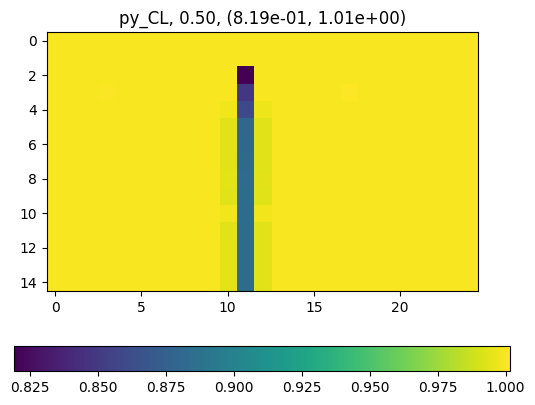

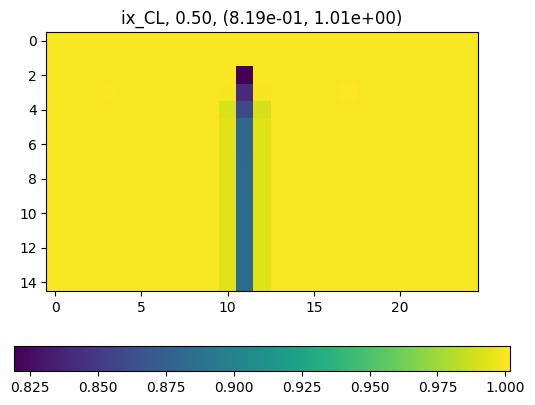

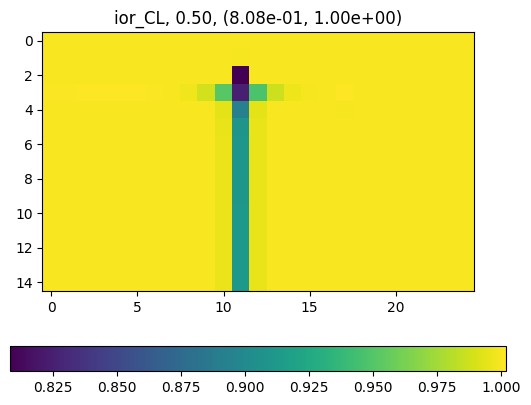

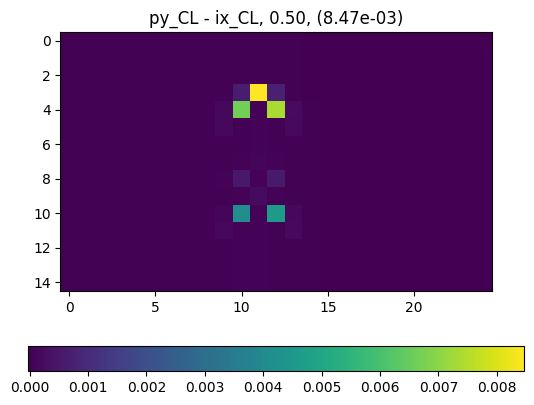

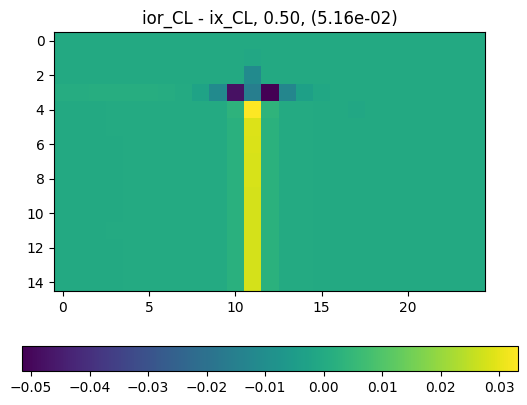

In [44]:
import numpy as np
import matplotlib.pyplot as pl
from ior2ecl import Output
from IORlib.Flow import unrstfile


#root = str(input['root'])
#name = input['name'].tolist()
#A = np.argwhere(flow.nnc.ijk[:,1] == 101)
#nnc_pos = tuple(zip(*flow.nnc.nnc[tuple(zip(*A))]))

# Compare tracer simulations
out = Output(root)

# Intersect
if IX:
    ix_data = out.slb_unrst.blockdata('DOUBHEAD', 0, *[f'TR{n}' for n in name], start=start)    
    ix_time, *ix_trc = next(ix_data)
    print('ix_time', ix_time)

# PyIOR
if PY:
    py_unrst = unrstfile(root)
    if timesync:
        steps = tuple(py_unrst.steps())
        days = tuple(py_unrst.days())
        ind = next(i for i,d in enumerate(days) if d >= ix_time)
        start = steps[ind]
    py_data = py_unrst.blockdata('DOUBHEAD', 0, *name, start=start)
    py_time, *py_trc = next(py_data)
    print('py_time', py_time)

# IORSim
if IOR:
    ior_data = out.ior_unrst.blockdata('DOUBHEAD', 0, *name, start=start)
    ior_time, *ior_trc = next(ior_data)
    print('ior_time', ior_time)

if PY:
    py = dict(zip(name, py_unrst.reshape_dim(*py_trc)))
if IOR:
    ior = dict(zip(name, out.ior_unrst.reshape_dim(*ior_trc)))
if IX:
    ix = dict(zip(name, out.slb_unrst.reshape_dim(*ix_trc)))

var = 'CL' #'WI'
#print(py_time, ix_time, ior_time)

pl.close('all')
args = {'rotate':rotate, 'aspect':aspect, 'clim':clim}

# Py
if PY:
    l, h, il, ih = min_max_3d(py[var])
    print('Py')
    print(f'min = {l:.4e} {il}')
    print(f'max = {h:.4e} {ih}')
    if nnc:
        py[var][*flow.nnc.ijk[0]] = np.nan
        py[var][*flow.nnc.ijk[1]] = np.nan
    if wells:
        py[var][*all_wpos] = np.nan
    if well_head:
        py[var][*whead] = np.nan
    if well_toe:
        py[var][*wtoe] = np.nan
    imshow(py[var][cut], f'py_{var}, {py_time:.2f}, ({l:.2e}, {h:.2e})', **args)

# IX
if IX:
    l, h, il, ih = min_max_3d(ix[var])
    print('IX')
    print(f'min = {l:.4e} {il}')
    print(f'max = {h:.4e} {ih}')
    imshow(ix[var][cut], f'ix_{var}, {ix_time:.2f}, ({l:.2e}, {h:.2e})', **args)

# IORSim
if IOR:
    l, h, il, ih = min_max_3d(ior[var])
    print('IOR')
    print(f'min = {l:.4e} {il}')
    print(f'max = {h:.4e} {ih}')
    imshow(ior[var][cut], f'ior_{var}, {ior_time:.2f}, ({l:.2e}, {h:.2e})', **args)

# Diff pyior - ix
if compare and PY and IX:
    diff = py[var] - ix[var]
    max_pos = np.unravel_index(np.argmax(np.abs(diff)), diff.shape)
    print('py: max diff at', tuple(map(int,max_pos)), '=' , diff[max_pos])
    imshow(diff[cut], f'py_{var} - ix_{var}, {ix_time:.2f}, ({np.max(np.abs(diff)):.2e})', **args)

# Diff ior - ix
if compare and IX and IOR:
    diff = ior[var] - ix[var]
    max_pos = np.unravel_index(np.argmax(np.abs(diff)), diff.shape)
    print('ior: max diff at', tuple(map(int,max_pos)), '=' , diff[max_pos])
    imshow(diff[cut], f'ior_{var} - ix_{var}, {ix_time:.2f}, ({np.max(np.abs(diff)):.2e})', **args)


In [38]:
list(py_unrst.days())
next(py_unrst.blockdata('DOUBHEAD', 0, start=0)), next(out.slb_unrst.blockdata('DOUBHEAD', 0, start=0)), next(out.ior_unrst.blockdata('DOUBHEAD', 0, start=0))

(np.float64(0.0), np.float64(0.0), np.float64(0.0))